# Hybrid Quantum-Classical Banknote Authentication

**Course:** NV62010 Quantum Computing with Artificial Intelligence. **Student:** Nausheen Parween (2023410855)

This notebook walks through the project step by step on **one** train/test split:

1. load the UCI Banknote Authentication data;
2. split it and scale it;
3. build the 4-qubit circuit;
4. train the classical baselines;
5. train the hybrid model;
6. evaluate both;
7. look at the effect of a finite number of measurement shots.

The full study in the report (10 splits, ablations, noise) is run with `python -m experiments.run_experiments`.

Runs in about 2 minutes on a laptop or in Google Colab.

## 0. Setup

**Google Colab:** run the next cell. It downloads the project and installs the pinned packages.

**Local Jupyter:** start Jupyter in the project folder after `pip install -r requirements.txt`, and skip the next cell.

In [1]:
import os, sys
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone -q https://github.com/Thefaizanhassan/mlAssignment.git
    %cd mlAssignment
    !pip install -q -r requirements.txt
elif not os.path.exists("src") and os.path.exists("../src"):
    os.chdir("..")          # started from the notebooks/ folder
print("working directory:", os.getcwd())

working directory: /home/user/mlAssignment


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from src import config
from src.data_preprocessing import load_banknote, get_arrays, make_split, AngleScaler, describe
from src.quantum_circuit import build_circuit, circuit_summary
from src.classical_models import build_baselines
from src.evaluation import compute_metrics, model_outputs
from src.hybrid_model import HybridQuantumClassifier

## 1. Load the dataset

1,372 banknotes and 4 wavelet features. Label 0 means genuine and 1 means forged. If the file is missing, it is downloaded from the UCI repository.

In [3]:
df = load_banknote()
print(df["class"].value_counts().rename({0: "genuine", 1: "forged"}))
describe(df)

class
genuine    762
forged     610
Name: count, dtype: int64


,mean,std,min,max,missing
variance,0.434,2.843,-7.042,6.825,0
skewness,1.922,5.869,-13.773,12.952,0
curtosis,1.398,4.310,-5.286,17.927,0
entropy,-1.192,2.101,-8.548,2.450,0


## 2. Split and scale

The split is stratified 80/20. Classical models get standardised features. The circuit gets **rotation angles in [0, π]**: one angle per feature, and therefore one qubit per feature. Both scalers are fitted on the training notes only.

In [4]:
X, y = get_arrays(df)
X_train, X_test, y_train, y_test = make_split(X, y, seed=config.SHOWCASE_SEED)
scaler = AngleScaler().fit(X_train)
A_train, A_test = scaler.transform(X_train), scaler.transform(X_test)
print(X_train.shape, X_test.shape)
print("first training note as angles:", A_train[0].round(3))

(1097, 4) (275, 4)
first training note as angles: [1.956 1.879 0.29  2.479]


## 3. The quantum circuit

Each of the 3 layers does three things:

1. **encode** the 4 angles with `RY(x)`;
2. apply 4 **trainable** `RY(θ)` rotations;
3. **entangle** neighbouring qubits with CNOTs.

The model then reads `<Z>` on every qubit.

{'qubits': 4, 'depth': 15, 'ry_gates': 24, 'cx_gates': 9, 'parameters': 16}


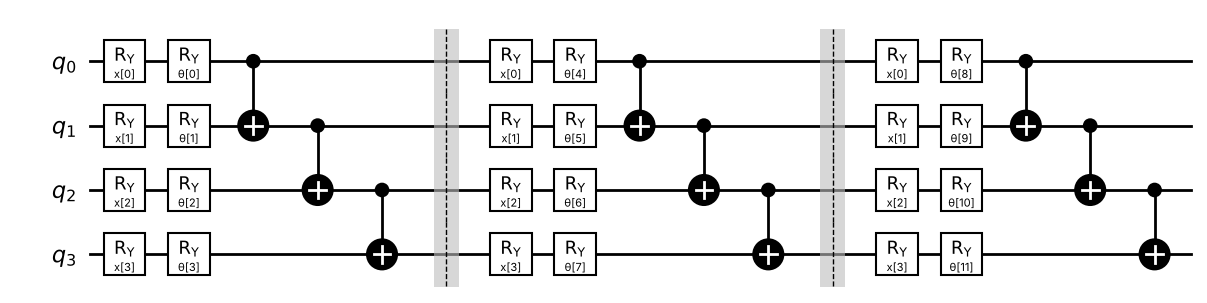

In [5]:
qc, x_params, theta_params = build_circuit(n_qubits=4, n_layers=3)
print(circuit_summary(qc))
qc.draw("mpl", fold=-1, style="bw")

## 4. Classical baselines

Five scikit-learn models with default settings.

In [6]:
baseline_results = {}
for name, model in build_baselines(seed=config.SHOWCASE_SEED).items():
    model.fit(X_train, y_train)
    y_pred, score = model_outputs(model, X_test)
    baseline_results[name] = compute_metrics(y_test, y_pred, score)
    print(f"{name:25s} accuracy = {baseline_results[name]['accuracy']:.4f}  F1 = {baseline_results[name]['f1']:.4f}")

Logistic Regression       accuracy = 0.9709  F1 = 0.9683
SVM (RBF kernel)          accuracy = 1.0000  F1 = 1.0000
k-Nearest Neighbours      accuracy = 1.0000  F1 = 1.0000
Random Forest             accuracy = 0.9964  F1 = 0.9959


Neural Network (4-4-1)    accuracy = 0.9782  F1 = 0.9760


## 5. Train the hybrid model

Each Adam step works as follows:

- run the circuit for 32 notes;
- run it again with every θ shifted by ±π/2 (the **parameter-shift rule**);
- combine the results into exact gradients;
- update the 12 circuit angles together with the 4 + 1 classical weights.

That is 800 circuit executions per step.

In [7]:
hybrid = HybridQuantumClassifier(n_layers=3, steps=300, seed=config.SHOWCASE_SEED, verbose=True, log_every=50)
hybrid.fit(A_train, y_train)
print(f"training time: {hybrid.fit_seconds:.1f} s, circuit executions: {hybrid.circuit_evaluations:,}")

  step    0 | circuits        0 | loss 0.6008 | train acc 0.6427


  step   50 | circuits    40000 | loss 0.1031 | train acc 0.9754


  step  100 | circuits    80000 | loss 0.0575 | train acc 0.9909


  step  150 | circuits   120000 | loss 0.0471 | train acc 0.9900


  step  200 | circuits   160000 | loss 0.0478 | train acc 0.9927


  step  250 | circuits   200000 | loss 0.0372 | train acc 0.9954


  step  300 | circuits   240000 | loss 0.0348 | train acc 0.9945
training time: 55.3 s, circuit executions: 240,000


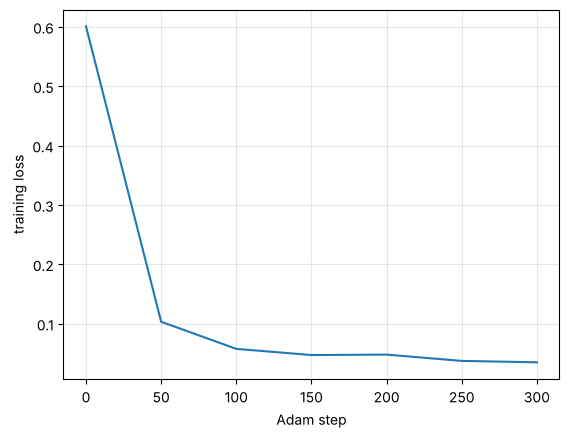

In [8]:
import pandas as pd
hist = pd.DataFrame(hybrid.history)
plt.plot(hist["step"], hist["loss"]); plt.xlabel("Adam step"); plt.ylabel("training loss"); plt.grid(alpha=.3); plt.show()

## 6. Evaluate on the test notes

In [9]:
prob = hybrid.predict_proba(A_test)
hybrid_metrics = compute_metrics(y_test, (prob >= 0.5).astype(int), prob)
table = pd.DataFrame({**baseline_results, "Hybrid VQC": hybrid_metrics}).T
table[["accuracy", "precision", "recall", "f1", "roc_auc", "tn", "fp", "fn", "tp"]].round(4)

,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
Logistic Regression,0.9709,0.9385,1.0,0.9683,0.9999,145.0,8.0,0.0,122.0
SVM (RBF kernel),1.0000,1.0000,1.0,1.0000,1.0000,153.0,0.0,0.0,122.0
k-Nearest Neighbours,1.0000,1.0000,1.0,1.0000,1.0000,153.0,0.0,0.0,122.0
Random Forest,0.9964,0.9919,1.0,0.9959,1.0000,152.0,1.0,0.0,122.0
Neural Network (4-4-1),0.9782,0.9531,1.0,0.9760,1.0000,147.0,6.0,0.0,122.0
Hybrid VQC,0.9891,0.9760,1.0,0.9879,1.0000,150.0,3.0,0.0,122.0


## 7. What changes with a finite number of shots?

Real hardware estimates `<Z>` from repeated measurements. Here the trained circuit is evaluated with 16 to 4,096 shots.

In [10]:
exact = hybrid.quantum_features(A_test)
for shots in (16, 64, 256, 1024, 4096):
    feats = hybrid.sampled_features(A_test, shots=shots, seed=1)
    acc = np.mean((hybrid.predict_proba_from_features(feats) >= 0.5) == y_test)
    print(f"{shots:5d} shots: accuracy = {acc:.4f}, mean |<Z> error| = {np.mean(np.abs(feats - exact)):.4f}")

   16 shots: accuracy = 0.9418, mean |<Z> error| = 0.1796
   64 shots: accuracy = 0.9818, mean |<Z> error| = 0.0923


  256 shots: accuracy = 0.9855, mean |<Z> error| = 0.0450


 1024 shots: accuracy = 0.9855, mean |<Z> error| = 0.0227


 4096 shots: accuracy = 0.9891, mean |<Z> error| = 0.0113


## Take-away

On this four-feature problem, the hybrid model reaches accuracy comparable to good classical models. It needs far more computation to do so: hundreds of thousands of circuit executions, against milliseconds of classical training.

This is a **simulation** study. It does not demonstrate quantum advantage; see Section 5 of the report for the full analysis.